# ATP Binding Interaction Analysis

**Goal:** Characterise how ATP binds across thousands of PDB structures, identify
conserved interaction archetypes, and find design handles for complementary binding
proteins that assemble in response to ATP.

## Workflow
| Step | What happens |
|---|---|
| 1 | Select PDB structures from the existing cache |
| 2 | Run **PLIP** on each structure to detect protein–ATP interactions |
| 3 | Parse H-bonds, hydrophobic contacts, π-stacking, salt bridges, metal coordination |
| 4 | Encode each structure as a binary interaction fingerprint |
| 5 | Cluster by fingerprint similarity (hierarchical, Jaccard distance) |
| 6 | Visualise as a Epiclus-style interaction heatmap |
| 7 | Profile each cluster: signature residues and interaction types |
| 8 | Identify which ATP moieties are most exposed → design recommendations |

---
**Checkpointing:** PLIP results are cached in `atp_binding_output/plip_results/` (one XML per
structure). Re-running Step 2 is instant for already-processed structures. The parsed
interaction table is also checkpointed as `atp_interactions.csv`.

## Environment setup (run once, then restart kernel)

Create a dedicated environment that has PLIP, RDKit, and analysis tools:

```bash
conda create -n atp_project_env python=3.11 -y
conda activate atp_project_env
conda install -c conda-forge openbabel rdkit -y
pip install plip biopython pandas numpy scipy matplotlib seaborn scikit-learn umap-learn tqdm
```

Then set this notebook's kernel to **atp_project_env**.

> Until the new environment is ready, the existing **epiclus_env** works for everything
> except RDKit. Set the kernel to `epiclus_env` via *Kernel → Change Kernel* in JupyterLab.

In [1]:
# ─── Parameters — edit before running ─────────────────────────────────────────
PDB_CACHE_DIR = 'top9fixed_structures'              # existing cache from conformer analysis
OUTPUT_DIR    = 'output/binding_fixedresidue'   # data output directory (sub-folder of output/)
PLOT_DIR      = 'pictures'          # PNG plots (shared with conformer analysis)

N_STRUCTURES  = None    # None = will pick up all 6 automatically 
N_WORKERS     = 6      # parallel PLIP threads (PLIP runs as subprocess → threads are fine)
N_CLUSTERS    = 6     # number of clusters for hierarchical clustering
MIN_CONTACTS  = 2      # discard structures with fewer distinct contact features
HEATMAP_FREQ  = 0.04   # minimum fraction of structures a feature must appear in to be shown

N_PYMOL_PER_CLUSTER = 1   # PDB structures to visualise per cluster (0 = skip)
PYMOL_SEED          = 42  # random seed for reproducible sampling

In [2]:
from pathlib import Path
for p in Path(PDB_CACHE_DIR).glob('*.pdb'):
    print(p)

top9fixed_structures/rank5_ATP_binding_8btg_ATP_binding_8btg_6_model_0_2_model_3.pdb
top9fixed_structures/rank6_ATP_binding_8btg_ATP_binding_8btg_3_model_0_1_model_0.pdb
top9fixed_structures/rank7_ATP_binding_8btg_ATP_binding_8btg_6_model_6_3_model_3.pdb
top9fixed_structures/rank9_ATP_binding_8btg_ATP_binding_8btg_4_model_0_10_model_0.pdb
top9fixed_structures/rank4_ATP_binding_8btg_ATP_binding_8btg_4_model_2_9_model_4.pdb
top9fixed_structures/rank3_ATP_binding_8btg_ATP_binding_8btg_0_model_9_3_model_0.pdb
top9fixed_structures/rank1_ATP_binding_8btg_ATP_binding_8btg_3_model_8_1_model_1.pdb
top9fixed_structures/rank2_ATP_binding_8btg_ATP_binding_8btg_1_model_1_5_model_3.pdb
top9fixed_structures/rank8_ATP_binding_8btg_ATP_binding_8btg_0_model_5_4_model_2.pdb


## Step 0 — Convert .cif.gz to .pdb
Automatically converts any compressed CIF files in the input folder to standard PDB format.

In [3]:
# Step 0 — Convert .cif.gz to .pdb if not already done
import gemmi
from pathlib import Path

for cif_gz in Path(PDB_CACHE_DIR).glob('*.cif.gz'):
    pdb_out = Path(str(cif_gz).replace('.cif.gz', '.pdb'))
    if not pdb_out.exists():
        st = gemmi.read_structure(str(cif_gz))
        st.write_pdb(str(pdb_out))
        print(f'Converted {cif_gz.name} → {pdb_out.name}')
    else:
        print(f'Already converted: {pdb_out.name}')

print('Conversion done.')

Already converted: rank6_ATP_binding_8btg_ATP_binding_8btg_3_model_0_1_model_0.pdb
Already converted: rank9_ATP_binding_8btg_ATP_binding_8btg_4_model_0_10_model_0.pdb
Already converted: rank3_ATP_binding_8btg_ATP_binding_8btg_0_model_9_3_model_0.pdb
Already converted: rank4_ATP_binding_8btg_ATP_binding_8btg_4_model_2_9_model_4.pdb
Already converted: rank5_ATP_binding_8btg_ATP_binding_8btg_6_model_0_2_model_3.pdb
Already converted: rank8_ATP_binding_8btg_ATP_binding_8btg_0_model_5_4_model_2.pdb
Already converted: rank7_ATP_binding_8btg_ATP_binding_8btg_6_model_6_3_model_3.pdb
Already converted: rank2_ATP_binding_8btg_ATP_binding_8btg_1_model_1_5_model_3.pdb
Already converted: rank1_ATP_binding_8btg_ATP_binding_8btg_3_model_8_1_model_1.pdb
Conversion done.


### 2b — PyMOL Visual Preferences

Embedded into every generated `.pse` session via the `pymol2` API.
Edit to match your `.pymolrc`.

In [4]:
PYMOL_SETTINGS = """
# Light / rendering
set specular, 0
set ray_shadow, off
set antialias, 2
set ray_trace_mode, 1
set ray_trace_disco_factor, 1
set ray_trace_gain, 0.1
set power, 0.2
set ambient, 0.4
set direct, 0.45
set cartoon_sampling, 10
set ray_trace_color, black
set seq_view, 1
set reflect, 1
set reflect_power, 0

# Structure
set ribbon_width, 8
set line_width, 2.5
set cartoon_transparency, 0.5
set cartoon_flat_sheets, off
set valence, off
set sphere_scale, 0.25
set sphere_transparency, 0.3

# Custom colours
set_color nitrogen, [2, 118, 253]
set_color oxygen, [160, 9, 9]
set_color pymol_gray, [51, 51, 51]
set_color pymol_black, [34, 34, 34]
set_color good_yellow, [250, 199, 44]
set_color good_teal, [40, 176, 193]
set_color good_pink, [236, 114, 164]
set_color good_peach, [249, 145, 120]
set_color good_blue, [68, 153, 231]
set_color good_gray, [220, 220, 220]
set_color good_red, [228, 74, 62]
set_color good_green, [26, 166, 2]
set_color good_magenta, [86, 15, 122]
set_color ipd_purple, [70, 50, 126]
set_color ipd_cyan, [87, 149, 178]
set_color ipd_magenta, [165, 50, 130]
set_color ipd_green, [25, 138, 83]
set_color ipd_orange, [187, 54, 17]
set_color paper_teal, [0.310, 0.725, 0.686]
set_color paper_navaho, [255, 224, 172]
set_color paper_melon, [255, 198, 178]
set_color paper_pink, [255, 172, 183]
set_color paper_purple, [213, 154, 181]
set_color paper_lightblue, [149, 150, 198]
set_color paper_blue, [102, 134, 197]
set_color paper_darkblue, [75, 95, 170]
set_color crest1, [0.506, 0.733, 0.565]
set_color crest2, [0.286, 0.596, 0.561]
set_color crest3, [0.149, 0.471, 0.545]
set_color crest4, [0.133, 0.318, 0.510]
set_color crest5, [0.173, 0.188, 0.443]
""".strip()

print('PYMOL_SETTINGS defined.')

PYMOL_SETTINGS defined.


In [5]:
%matplotlib inline
import os, sys, json, subprocess, shutil
import xml.etree.ElementTree as ET
from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor, as_completed

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.spatial.distance import pdist
from tqdm import tqdm

Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)
Path(PLOT_DIR).mkdir(exist_ok=True)

# Detect PLIP executable in the active conda environment
PLIP_EXE = shutil.which('plip') or os.path.join(os.path.dirname(sys.executable), 'plip')
if not Path(PLIP_EXE).exists():
    raise EnvironmentError(
        f"PLIP not found at '{PLIP_EXE}'.\n"
        "Install it with:  conda install -c conda-forge openbabel && pip install plip"
    )
print(f'PLIP executable : {PLIP_EXE}')

AA3 = {
    'ALA':'A','ARG':'R','ASN':'N','ASP':'D','CYS':'C','GLN':'Q','GLU':'E',
    'GLY':'G','HIS':'H','ILE':'I','LEU':'L','LYS':'K','MET':'M','PHE':'F',
    'PRO':'P','SER':'S','THR':'T','TRP':'W','TYR':'Y','VAL':'V'
}

# Human-readable labels for PLIP interaction group tags
ITYPE_LABEL = {
    'hydrogen_bonds':         'HBond',
    'hydrophobic_interactions':'HPhob',
    'salt_bridges':           'Salt',
    'pi_stacks':              'PiStack',
    'pi_cation_interactions':  'PiCat',
    'metal_complexes':        'Metal',
    'water_bridges':          'WaterBr',
    'halogen_bonds':          'Halogen',
}

ITYPE_COLOR = {
    'HBond':   '#1f77b4',
    'HPhob':   '#2ca02c',
    'Salt':    '#d62728',
    'PiStack': '#ff7f0e',
    'PiCat':   '#9467bd',
    'Metal':   '#8c564b',
    'WaterBr': '#17becf',
    'Halogen': '#e377c2',
}

print('Setup OK.')

PLIP executable : /zhome/e8/5/223639/miniforge3/envs/atp_project_env/bin/plip
Setup OK.


## Helper functions
Run once — used across all steps below.

In [6]:

# ATP atom → structural moiety mapping
ATP_MOIETY = {
    # Gamma phosphate (most distal, hydrolysed by ATPases)
    'PG':  'gamma-PO4', 'O1G': 'gamma-PO4', 'O2G': 'gamma-PO4', 'O3G': 'gamma-PO4',
    'O3B': 'gamma-PO4',  # bridging O between beta and gamma phosphates
    # Beta phosphate
    'PB':  'beta-PO4',  'O1B': 'beta-PO4',  'O2B': 'beta-PO4',
    'O3A': 'beta-PO4',  # bridging O between alpha and beta phosphates
    # Alpha phosphate
    'PA':  'alpha-PO4', 'O1A': 'alpha-PO4', 'O2A': 'alpha-PO4',
    # Ribose sugar
    "C1'": 'ribose', "C2'": 'ribose', "C3'": 'ribose', "C4'": 'ribose',
    "C5'": 'ribose', "O4'": 'ribose', "O2'": 'ribose', "O3'": 'ribose',
    "O5'": 'ribose',
    # Adenine base
    'N1': 'adenine', 'C2': 'adenine', 'N3': 'adenine', 'C4': 'adenine',
    'C5': 'adenine', 'C6': 'adenine', 'N6': 'adenine', 'N7': 'adenine',
    'C8': 'adenine', 'N9': 'adenine',
}

MOIETY_ORDER = ['gamma-PO4', 'beta-PO4', 'alpha-PO4', 'ribose', 'adenine', 'other']

MOIETY_COLOR = {
    'gamma-PO4':  '#d62728',
    'beta-PO4':   '#ff7f0e',
    'alpha-PO4':  '#e8c32e',
    'ribose':     '#2ca02c',
    'adenine':    '#1f77b4',
    'other':      '#999999',
}

def atp_moiety(atom_name: str) -> str:
    """Map an ATP atom name to its structural moiety."""
    a = atom_name.strip().upper().replace('*', "'")   # normalise PDB * → '
    return ATP_MOIETY.get(a, 'other')


def _extract_atp_atom(item, igroup_tag: str) -> str:
    """Extract the ATP atom name from a PLIP interaction XML element."""
    # Most types store the ligand atom directly in <ligatom>
    atom = item.findtext('ligatom', '').strip()
    if atom:
        return atom
    # Salt bridges list atoms under <lig_atoms><atom>…</atom></lig_atoms>
    if igroup_tag == 'salt_bridges':
        lig_atoms = item.find('lig_atoms')
        if lig_atoms is not None:
            first = lig_atoms.find('atom')
            if first is not None and first.text:
                return first.text.strip()
        return item.findtext('lig_group', '').strip()
    # Pi interactions reference a ring rather than a single atom
    if igroup_tag in ('pi_stacks', 'pi_cation_interactions'):
        return item.findtext('lig_group', 'ring').strip() or 'ring'
    return ''


def run_plip(pdb_path: str, plip_dir: str) -> str | None:
    """Run PLIP on a PDB file; return path to *_report.xml, or None on failure."""
    Path(plip_dir).mkdir(parents=True, exist_ok=True)
    existing = list(Path(plip_dir).glob('*_report.xml'))
    if existing:
        return str(existing[0])
    try:
        subprocess.run(
            [PLIP_EXE, '-f', str(pdb_path), '-x', '-o', str(plip_dir)],
            capture_output=True, text=True, timeout=120, check=True,
        )
    except Exception:
        return None
    found = list(Path(plip_dir).glob('*_report.xml'))
    return str(found[0]) if found else None


def parse_atp_xml(xml_path: str, pdb_id: str) -> pd.DataFrame:
    """Parse a PLIP XML report; return a DataFrame of ATP-protein interactions.

    Columns include atp_atom (PLIP atom name) and atp_moiety (structural region).
    """
    try:
        root = ET.parse(xml_path).getroot()
    except Exception:
        return pd.DataFrame()

    records = []
    for bs in root.findall('.//bindingsite'):
        if bs.findtext('./identifiers/hetid', '') != 'ATP':
            continue
        atp_id = (f"{bs.findtext('./identifiers/chain','')}:"
                  f"{bs.findtext('./identifiers/position','')}")
        interacts = bs.find('interactions')
        if interacts is None:
            continue

        for igroup in interacts:
            raw   = igroup.tag
            label = ITYPE_LABEL.get(raw, raw)
            for item in igroup:
                resnr    = item.findtext('resnr',    '')
                restype  = item.findtext('restype',  '')
                reschain = item.findtext('reschain', '')

                if raw == 'hydrogen_bonds':
                    pdon  = item.findtext('protisdon', 'True')
                    label = 'HBond_Don' if pdon == 'True' else 'HBond_Acc'

                atom_name = _extract_atp_atom(item, raw)
                moiety    = atp_moiety(atom_name)

                records.append({
                    'pdb_id':    pdb_id,
                    'atp_id':    atp_id,
                    'res_nr':    resnr,
                    'res_type':  restype,
                    'res_1':     AA3.get(restype, 'X'),
                    'itype':     label,
                    'itype_raw': raw,
                    'atp_atom':  atom_name,
                    'atp_moiety': moiety,
                })
    return pd.DataFrame(records)


def _worker(pdb_id: str) -> tuple:
    """Thread worker: run PLIP + parse for one PDB. Returns (pdb_id, df | None)."""
    pdb_path = Path(PDB_CACHE_DIR) / f'{pdb_id}.pdb'
    if not pdb_path.exists():
        return pdb_id, None
    plip_dir = Path(OUTPUT_DIR) / 'plip_results' / pdb_id
    xml_path = run_plip(str(pdb_path), str(plip_dir))
    if xml_path is None:
        return pdb_id, None
    df = parse_atp_xml(xml_path, pdb_id)
    return pdb_id, df if not df.empty else None


print('Helper functions loaded.')


Helper functions loaded.


---
## Step 1 — Select structures
Reads PDB IDs directly from the cache built during conformer analysis.
Set `N_STRUCTURES = None` to process all ~3,500 structures (takes ~2–4 h).

In [7]:
all_pdb_ids = sorted(p.stem for p in Path(PDB_CACHE_DIR).glob('*.pdb'))
print(f'PDB files in cache: {len(all_pdb_ids):,}')

pdb_ids = all_pdb_ids[:N_STRUCTURES] if N_STRUCTURES else all_pdb_ids
print(f'Selected for analysis: {len(pdb_ids):,}'
      + (f'  (set N_STRUCTURES=None to use all)' if N_STRUCTURES else ''))

PDB files in cache: 9
Selected for analysis: 9


---
## Step 2 — Run PLIP

PLIP analyses the complete protein structure and detects all interactions between
the ATP ligand and surrounding protein residues:
hydrogen bonds (donor / acceptor), hydrophobic contacts, π-stacking,
π-cation, salt bridges, metal coordination, and water-mediated H-bonds.

Each structure's result is cached as an XML file — re-running this cell is fast
for structures already processed.

In [8]:
PLIP_DIR = Path(OUTPUT_DIR) / 'plip_results'
n_cached = sum(1 for pid in pdb_ids
               if (PLIP_DIR / pid / 'report.xml').exists())
print(f'Running PLIP on {len(pdb_ids)} structures  '
      f'({n_cached} already cached, {len(pdb_ids)-n_cached} to compute)')
print(f'Workers: {N_WORKERS}  |  estimated time for new runs: '
      f'~{max(0,(len(pdb_ids)-n_cached))*4//N_WORKERS//60} min')

results = {}
failed  = []

with ThreadPoolExecutor(max_workers=N_WORKERS) as pool:
    futures = {pool.submit(_worker, pid): pid for pid in pdb_ids}
    for fut in tqdm(as_completed(futures), total=len(pdb_ids), desc='PLIP'):
        pid, df = fut.result()
        if df is not None:
            results[pid] = df
        else:
            failed.append(pid)

print(f'\nSucceeded: {len(results):,}  |  Failed / no ATP found: {len(failed):,}')

Running PLIP on 9 structures  (0 already cached, 9 to compute)
Workers: 6  |  estimated time for new runs: ~0 min


PLIP: 100%|██████████| 9/9 [00:00<00:00, 51289.04it/s]


Succeeded: 9  |  Failed / no ATP found: 0


---
## Step 3 — Interaction dataframe
Combines all per-structure results into one master table and saves it as a CSV
checkpoint. Loads from checkpoint if it already exists.

In [9]:
CSV_PATH = Path(OUTPUT_DIR) / 'atp_interactions.csv'

if results:
    df_all = pd.concat(results.values(), ignore_index=True)
    df_all.to_csv(CSV_PATH, index=False)
    print(f'Saved {len(df_all):,} interaction records to {CSV_PATH}')
elif CSV_PATH.exists():
    df_all = pd.read_csv(CSV_PATH)
    print(f'Loaded {len(df_all):,} records from checkpoint {CSV_PATH}')
else:
    raise RuntimeError('No results and no checkpoint found. Run Step 2 first.')

print(f'Structures with ATP contacts: {df_all["pdb_id"].nunique():,}')
print()
print('Interaction type breakdown:')
print(df_all['itype'].value_counts().to_string())
print()
print('Top 12 contacting residue types:')
print(df_all['res_type'].value_counts().head(12).to_string())

Saved 101 interaction records to output/binding_fixedresidue/atp_interactions.csv
Structures with ATP contacts: 9

Interaction type breakdown:
itype
HBond_Don    48
Salt         33
HBond_Acc    18
PiCat         1
PiStack       1

Top 12 contacting residue types:
res_type
ARG    41
GLY    16
VAL     8
LYS     6
SER     5
THR     4
LEU     4
GLN     4
ALA     3
GLU     3
PHE     2
TYR     2


---
## Step 4 — Interaction fingerprints

Each structure is encoded as a **binary vector** where each feature is a
(residue_type, interaction_type) pair. A `1` means at least one residue of that
type makes that interaction type with ATP in this structure.

This representation ignores copy number and focuses on the *types* of contacts present,
making it robust to differences in the number of ATP copies per structure.

In [10]:
# Build binary fingerprint matrix: rows = structures, columns = (res_type, itype)
fp_raw = (
    df_all
    .groupby(['pdb_id', 'res_type', 'itype'])
    .size()
    .reset_index(name='count')
    .pivot_table(index='pdb_id', columns=['res_type', 'itype'],
                 values='count', aggfunc='sum')
    .fillna(0)
    .gt(0)
    .astype(int)
)

# Filter: keep structures with >= MIN_CONTACTS distinct contact features
richness = fp_raw.sum(axis=1)
fp = fp_raw[richness >= MIN_CONTACTS].copy()

print(f'Fingerprint matrix: {fp_raw.shape[0]} structures  x  {fp_raw.shape[1]} features')
print(f'After filter (>= {MIN_CONTACTS} features): {fp.shape[0]} structures kept')
print()
print('Most common features (top 20):')
top_feats = fp.sum().sort_values(ascending=False).head(20)
for (res, itype), count in top_feats.items():
    pct = count / fp.shape[0] * 100
    print(f'  {res:4s} + {itype:10s}  {count:4d}  ({pct:.0f}%)')

Fingerprint matrix: 9 structures  x  26 features
After filter (>= 2 features): 9 structures kept

Most common features (top 20):
  GLY  + HBond_Don      8  (89%)
  ARG  + Salt           8  (89%)
  ARG  + HBond_Don      6  (67%)
  SER  + HBond_Don      4  (44%)
  GLY  + HBond_Acc      3  (33%)
  GLN  + HBond_Don      3  (33%)
  VAL  + HBond_Acc      3  (33%)
  VAL  + HBond_Don      3  (33%)
  LEU  + HBond_Don      3  (33%)
  ALA  + HBond_Don      2  (22%)
  TYR  + HBond_Acc      2  (22%)
  LYS  + HBond_Don      2  (22%)
  LYS  + Salt           2  (22%)
  GLU  + HBond_Acc      2  (22%)
  THR  + HBond_Don      2  (22%)
  GLU  + HBond_Don      1  (11%)
  ARG  + HBond_Acc      1  (11%)
  ARG  + PiCat          1  (11%)
  PHE  + HBond_Don      1  (11%)
  MET  + HBond_Acc      1  (11%)


---
## Step 5 — Hierarchical clustering

Skipping because not relevant for this
Structures are clustered using Ward linkage on Jaccard distances between fingerprints.
Jaccard distance is appropriate for binary data: it measures the fraction of features
that differ between two structures.

In [11]:
#X = fp.values.astype(float)
#Z = linkage(pdist(X, metric='jaccard'), method='ward')

#cluster_ids = fcluster(Z, t=N_CLUSTERS, criterion='maxclust')
#fp['cluster'] = cluster_ids

# Reorder rows by dendrogram leaf order
#leaf_order = dendrogram(Z, no_plot=True)['leaves']
#fp_ordered  = fp.iloc[leaf_order].copy()

#print('Cluster sizes:')
#for cid, count in sorted(pd.Series(cluster_ids).value_counts().sort_index().items()):
   # print(f'  Cluster {cid}: {count} structures')

# Save cluster assignments
#fp[['cluster']].to_csv(Path(OUTPUT_DIR) / 'cluster_assignments.csv')
#print('\nSaved cluster assignments.')

---
## Step 6 — Interaction heatmap

Rows = interaction features (residue × interaction type), columns = PDB structures
sorted by cluster membership. Vertical coloured bars on top mark cluster boundaries.

Only features present in at least `HEATMAP_FREQ` of all structures are shown,
to keep the plot readable.

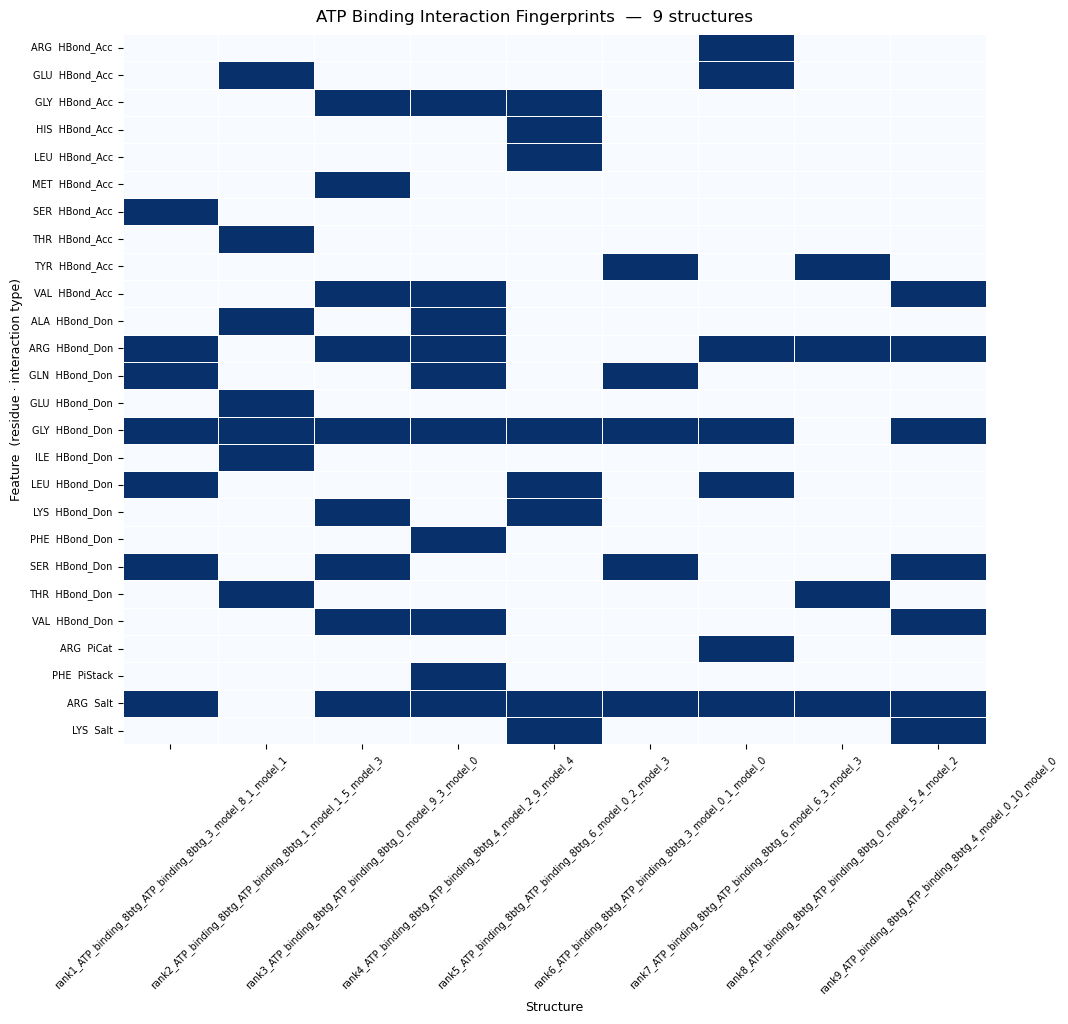

Saved interaction_heatmap.png


In [12]:
# Step 6 — Interaction heatmap (per structure, no clustering)
plot_data = fp.T  # features as rows, structures as columns

# Keep only common features
freq_mask = plot_data.sum(axis=1) / plot_data.shape[1] >= HEATMAP_FREQ
plot_data = plot_data[freq_mask]

# Sort features by interaction type
plot_data = plot_data.sort_index(level='itype')

fig_h = max(8, len(plot_data) * 0.4)
fig_w = max(8, fp.shape[0] * 1.2)
fig, ax_main = plt.subplots(figsize=(fig_w, fig_h))

sns.heatmap(
    plot_data,
    ax=ax_main,
    cmap='Blues',
    cbar=False,
    linewidths=0.5,
    xticklabels=[s for s in plot_data.columns],
    yticklabels=[f'{r}  {i}' for r, i in plot_data.index],
)
ax_main.set_ylabel('Feature  (residue · interaction type)', fontsize=9)
ax_main.set_xlabel('Structure', fontsize=9)
ax_main.tick_params(axis='x', labelsize=7, rotation=45)
ax_main.tick_params(axis='y', labelsize=7)

fig.suptitle(
    f'ATP Binding Interaction Fingerprints  —  {fp.shape[0]} structures',
    fontsize=12
)
plt.tight_layout()
fig.savefig(Path(PLOT_DIR) / 'interaction_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved interaction_heatmap.png')

---
## Step 7 — Per-cluster interaction profiles

For each cluster: bar chart of the most frequent (residue type, interaction type)
combinations. This shows the *signature contacts* that define each binding archetype.

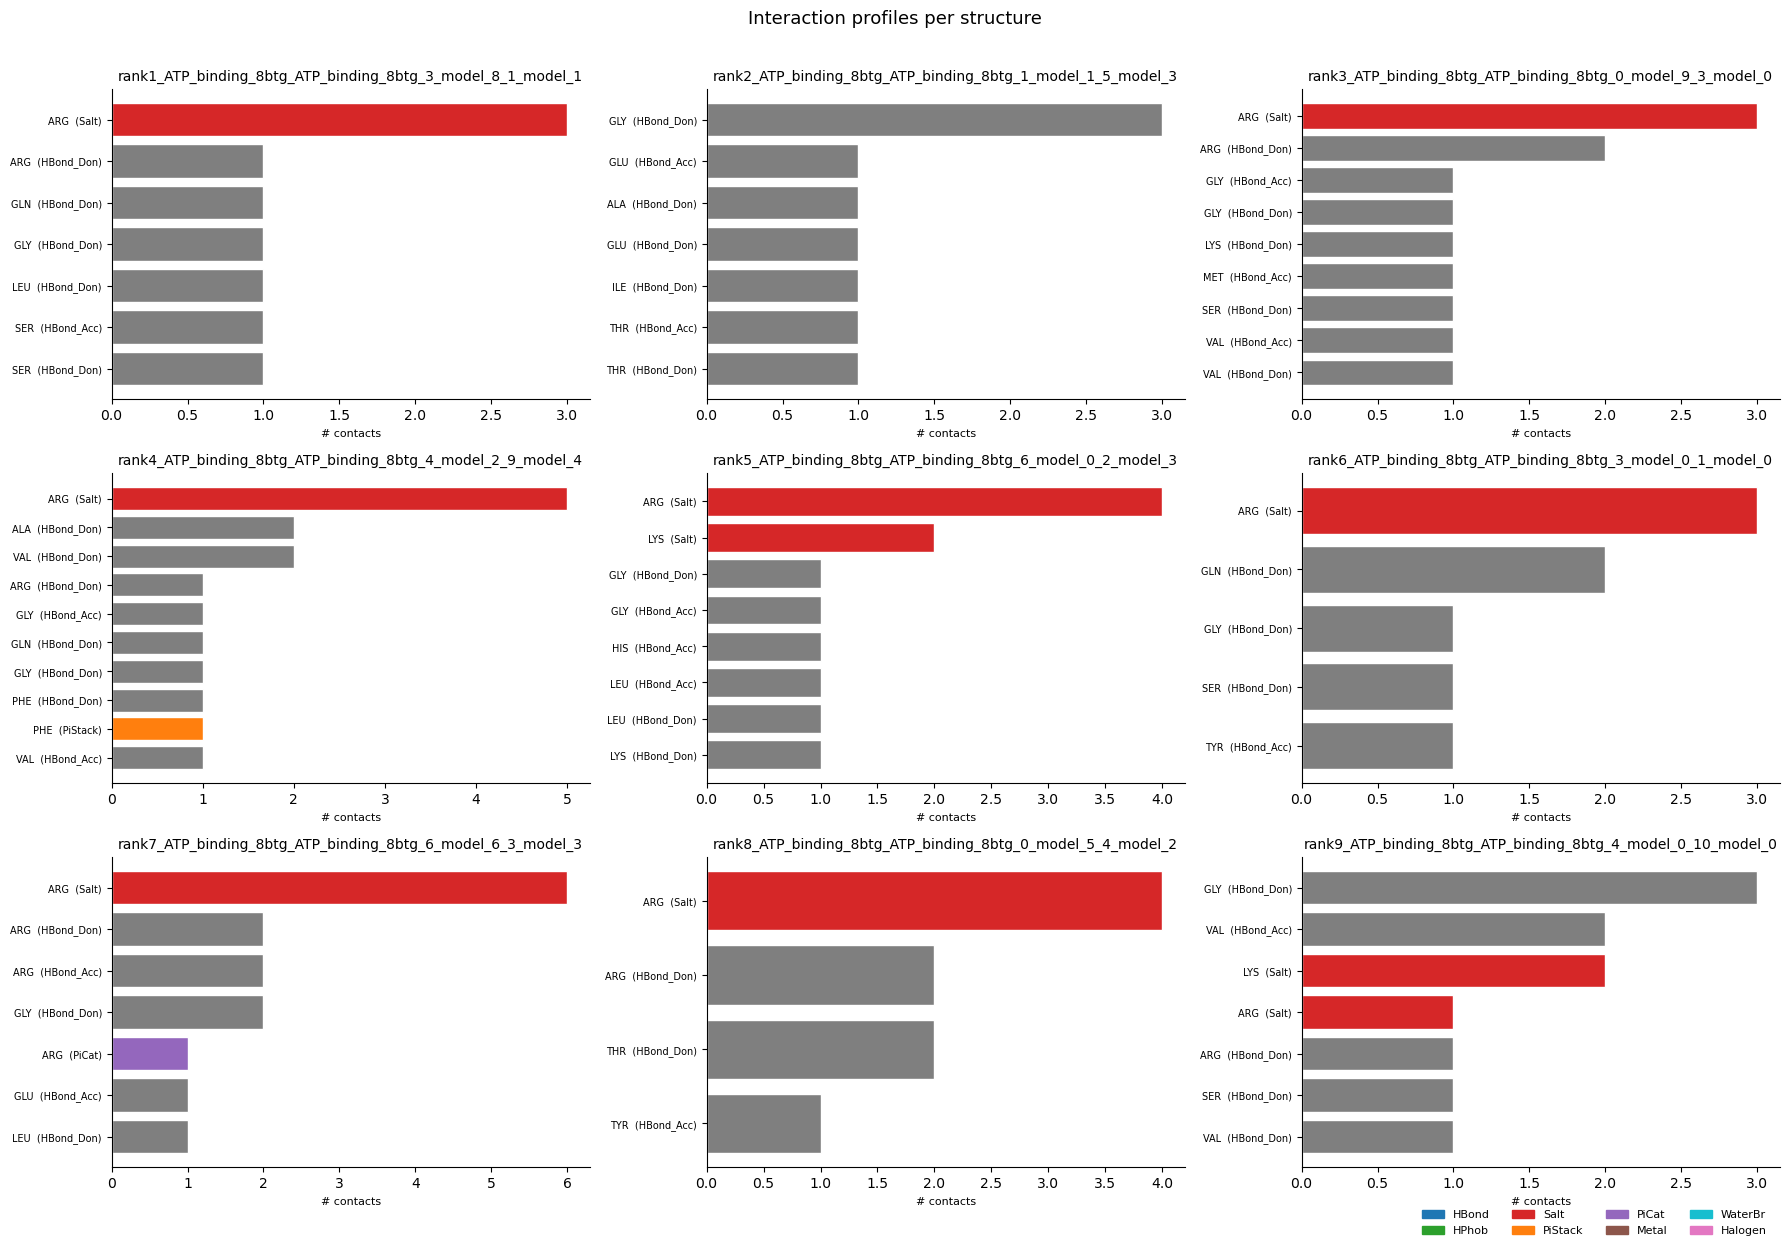

Saved structure_profiles.png


In [13]:
%matplotlib inline
# Step 7 — Per-structure interaction profiles
n_cols = 3
n_rows = (len(pdb_ids) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4 * n_rows))
axes = np.array(axes).flatten()

for idx, pdb_id in enumerate(fp.index):
    ax = axes[idx]
    struct_df = df_all[df_all['pdb_id'] == pdb_id]

    feat_freq = (
        struct_df.groupby(['res_type', 'itype'])
                 .size()
                 .reset_index(name='n')
                 .sort_values('n', ascending=False)
                 .head(12)
    )

    bar_colors = [ITYPE_COLOR.get(i, '#7f7f7f') for i in feat_freq['itype']]
    ax.barh(range(len(feat_freq)), feat_freq['n'], color=bar_colors, edgecolor='white')
    ax.set_yticks(range(len(feat_freq)))
    ax.set_yticklabels(
        [f'{r}  ({i})' for r, i in zip(feat_freq['res_type'], feat_freq['itype'])],
        fontsize=7
    )
    ax.invert_yaxis()
    ax.set_title(pdb_id, fontsize=10)
    ax.set_xlabel('# contacts', fontsize=8)
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

for ax in axes[len(fp.index):]:
    ax.set_visible(False)

handles = [mpatches.Patch(color=c, label=k) for k, c in ITYPE_COLOR.items()]
fig.legend(handles=handles, loc='lower right', fontsize=8,
           ncol=4, bbox_to_anchor=(0.99, -0.02), frameon=False)

fig.suptitle('Interaction profiles per structure', fontsize=13, y=1.01)
plt.tight_layout()
fig.savefig(Path(PLOT_DIR) / 'structure_profiles.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved structure_profiles.png')

---
## Step 8 — Global interaction summary

Which residue types and interaction types are most universally conserved across all
binding modes? High conservation = likely load-bearing for ATP recognition.
Low conservation = variable, potentially designable.

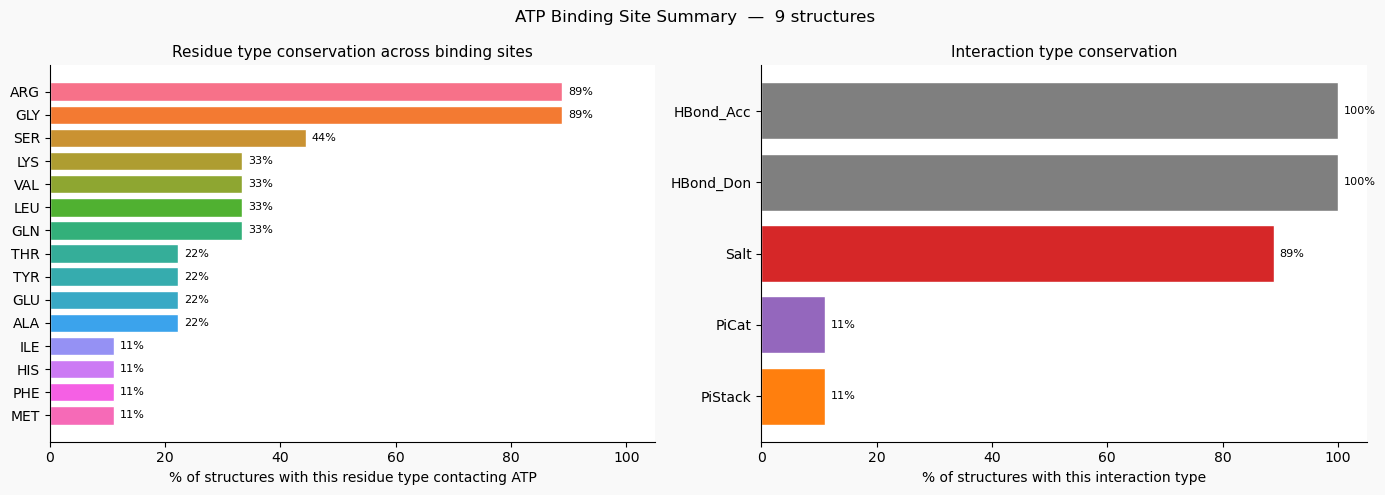

Saved interaction_summary.png


In [14]:
n_structs = df_all['pdb_id'].nunique()

# Conservation: % of structures with at least one contact of this residue type
res_conservation = (
    df_all.drop_duplicates(['pdb_id', 'res_type'])
          .groupby('res_type')['pdb_id']
          .count()
          .sort_values(ascending=False)
          / n_structs * 100
).head(15)

itype_conservation = (
    df_all.drop_duplicates(['pdb_id', 'itype'])
          .groupby('itype')['pdb_id']
          .count()
          .sort_values(ascending=False)
          / n_structs * 100
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor('#f9f9f9')

# Residue conservation
palette = sns.color_palette('husl', len(res_conservation))
axes[0].barh(res_conservation.index, res_conservation.values,
             color=palette, edgecolor='white')
axes[0].set_xlabel('% of structures with this residue type contacting ATP')
axes[0].set_title('Residue type conservation across binding sites', fontsize=11)
axes[0].invert_yaxis()
axes[0].set_xlim(0, 105)
for v, label in zip(res_conservation.values, res_conservation.index):
    axes[0].text(v + 1, label, f'{v:.0f}%', va='center', fontsize=8)
for spine in ['top', 'right']:
    axes[0].spines[spine].set_visible(False)

# Interaction type conservation
icolors = [ITYPE_COLOR.get(i, '#7f7f7f') for i in itype_conservation.index]
axes[1].barh(itype_conservation.index, itype_conservation.values,
             color=icolors, edgecolor='white')
axes[1].set_xlabel('% of structures with this interaction type')
axes[1].set_title('Interaction type conservation', fontsize=11)
axes[1].invert_yaxis()
axes[1].set_xlim(0, 105)
for v, label in zip(itype_conservation.values, itype_conservation.index):
    axes[1].text(v + 1, label, f'{v:.0f}%', va='center', fontsize=8)
for spine in ['top', 'right']:
    axes[1].spines[spine].set_visible(False)

plt.suptitle(f'ATP Binding Site Summary  \u2014  {n_structs} structures', fontsize=12)
plt.tight_layout()
fig.savefig(Path(PLOT_DIR) / 'interaction_summary.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved interaction_summary.png')

In [15]:
print(df_all['atp_moiety'].value_counts())
print(df_all['atp_atom'].value_counts().head(20))

atp_moiety
other    101
Name: count, dtype: int64
atp_atom
             66
Phosphate    33
Aromatic      1
ring          1
Name: count, dtype: int64


# Solvent Accessible Surface Area Analysis

In [18]:
# Step 8c — Solvent Accessible Surface Area (SASA) analysis
import freesasa

SASA_DIR = Path(OUTPUT_DIR) / 'sasa'
SASA_DIR.mkdir(parents=True, exist_ok=True)

results_sasa = []

for pdb_path in sorted(Path(PDB_CACHE_DIR).glob('*.pdb')):
    pdb_id = pdb_path.stem

    structure = freesasa.Structure(str(pdb_path), options={'hetatm': True})
    result = freesasa.calc(structure)

    selections = freesasa.selectArea(
        ['atp, resn ATP'],
        structure, result
    )
    atp_sasa = selections.get('atp', 0)
    total_sasa = result.totalArea()

    results_sasa.append({
        'pdb_id': pdb_id,
        'atp_sasa': atp_sasa,
        'total_sasa': total_sasa,
        'atp_burial_pct': (1 - atp_sasa / total_sasa) * 100
    })

df_sasa = pd.DataFrame(results_sasa)
df_sasa.to_csv(Path(OUTPUT_DIR) / 'sasa_results.csv', index=False)
print(df_sasa.to_string(index=False))



FreeSASA: warning: atom 'ATP  PG ' unknown, guessing element is ' P', and radius 1.800 A
FreeSASA: warning: atom 'ATP  O1G' unknown, guessing element is ' O', and radius 1.520 A
FreeSASA: warning: atom 'ATP  O2G' unknown, guessing element is ' O', and radius 1.520 A
FreeSASA: warning: atom 'ATP  O3G' unknown, guessing element is ' O', and radius 1.520 A
FreeSASA: warning: atom 'ATP  PB ' unknown, guessing element is ' P', and radius 1.800 A
FreeSASA: warning: atom 'ATP  O1B' unknown, guessing element is ' O', and radius 1.520 A
FreeSASA: warning: atom 'ATP  O2B' unknown, guessing element is ' O', and radius 1.520 A
FreeSASA: warning: atom 'ATP  O3B' unknown, guessing element is ' O', and radius 1.520 A
FreeSASA: warning: atom 'ATP  PA ' unknown, guessing element is ' P', and radius 1.800 A
FreeSASA: warning: atom 'ATP  O1A' unknown, guessing element is ' O', and radius 1.520 A
FreeSASA: warning: atom 'ATP  O2A' unknown, guessing element is ' O', and radius 1.520 A
FreeSASA: warning: at

                                                      pdb_id   atp_sasa  total_sasa  atp_burial_pct
 rank1_ATP_binding_8btg_ATP_binding_8btg_3_model_8_1_model_1 336.036465 7972.429553       95.785018
 rank2_ATP_binding_8btg_ATP_binding_8btg_1_model_1_5_model_3  83.558993 6839.388376       98.778268
 rank3_ATP_binding_8btg_ATP_binding_8btg_0_model_9_3_model_0 123.250762 8038.675433       98.466778
 rank4_ATP_binding_8btg_ATP_binding_8btg_4_model_2_9_model_4  17.744468 7058.771691       99.748618
 rank5_ATP_binding_8btg_ATP_binding_8btg_6_model_0_2_model_3 208.692072 7467.405490       97.205293
 rank6_ATP_binding_8btg_ATP_binding_8btg_3_model_0_1_model_0 306.482394 7259.492000       95.778184
 rank7_ATP_binding_8btg_ATP_binding_8btg_6_model_6_3_model_3  79.862487 7532.101292       98.939705
 rank8_ATP_binding_8btg_ATP_binding_8btg_0_model_5_4_model_2 217.239716 7979.707421       97.277598
rank9_ATP_binding_8btg_ATP_binding_8btg_4_model_0_10_model_0  88.248265 7339.011859       98.797546


is ' C', and radius 1.700 A
FreeSASA: warning: atom 'ATP  N7 ' unknown, guessing element is ' N', and radius 1.550 A
FreeSASA: warning: atom 'ATP  C5 ' unknown, guessing element is ' C', and radius 1.700 A
FreeSASA: warning: atom 'ATP  C6 ' unknown, guessing element is ' C', and radius 1.700 A
FreeSASA: warning: atom 'ATP  N6 ' unknown, guessing element is ' N', and radius 1.550 A
FreeSASA: warning: atom 'ATP  N1 ' unknown, guessing element is ' N', and radius 1.550 A
FreeSASA: warning: atom 'ATP  C2 ' unknown, guessing element is ' C', and radius 1.700 A
FreeSASA: warning: atom 'ATP  N3 ' unknown, guessing element is ' N', and radius 1.550 A
FreeSASA: warning: atom 'ATP  C4 ' unknown, guessing element is ' C', and radius 1.700 A
FreeSASA: warning: atom 'ATP  PG ' unknown, guessing element is ' P', and radius 1.800 A
FreeSASA: warning: atom 'ATP  O1G' unknown, guessing element is ' O', and radius 1.520 A
FreeSASA: warning: atom 'ATP  O2G' unknown, guessing element is ' O', and radius 1

# Plot

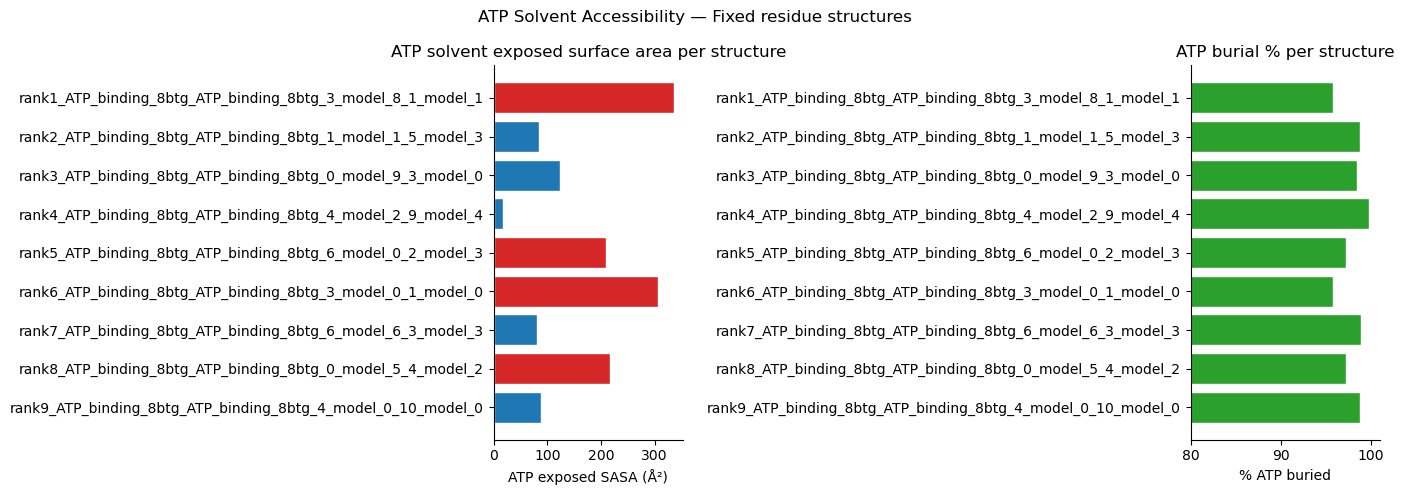

Saved sasa_analysis_fixed.png


In [19]:
# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = ['#d62728' if v > 200 else '#1f77b4' for v in df_sasa['atp_sasa']]
axes[0].barh(df_sasa['pdb_id'], df_sasa['atp_sasa'], color=colors, edgecolor='white')
axes[0].set_xlabel('ATP exposed SASA (Å²)')
axes[0].set_title('ATP solvent exposed surface area per structure')
axes[0].invert_yaxis()
for spine in ['top', 'right']:
    axes[0].spines[spine].set_visible(False)

axes[1].barh(df_sasa['pdb_id'], df_sasa['atp_burial_pct'], color='#2ca02c', edgecolor='white')
axes[1].set_xlabel('% ATP buried')
axes[1].set_title('ATP burial % per structure')
axes[1].set_xlim(80, 101)
axes[1].invert_yaxis()
for spine in ['top', 'right']:
    axes[1].spines[spine].set_visible(False)

plt.suptitle('ATP Solvent Accessibility — Fixed residue structures', fontsize=12)
plt.tight_layout()
plt.savefig(Path(PLOT_DIR) / 'sasa_analysis_fixed.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved sasa_analysis_fixed.png')

---
## Step 8b — ATP atom-level contact analysis

Which **atoms of ATP** are actually contacted by the protein — and by what interaction
types? This resolves the phosphate chain, ribose, and adenine base as separate handles.

**Why this matters for design:**
- γ-phosphate contacts are almost always present in ATPases/kinases but absent in
  binding-only proteins → a designed sensor that distinguishes ATP from ADP must
  engage here.
- Adenine contacts (N1, N7, N6) determine nucleotide specificity vs GTP.
- Ribose 2'-OH is the ATP-vs-dATP discriminator.
- Heavy coverage on the γ-phosphate face and sparse adenine coverage indicates
  that the base face is available for a complementary binder.

ValueError: zero-size array to reduction operation fmin which has no identity

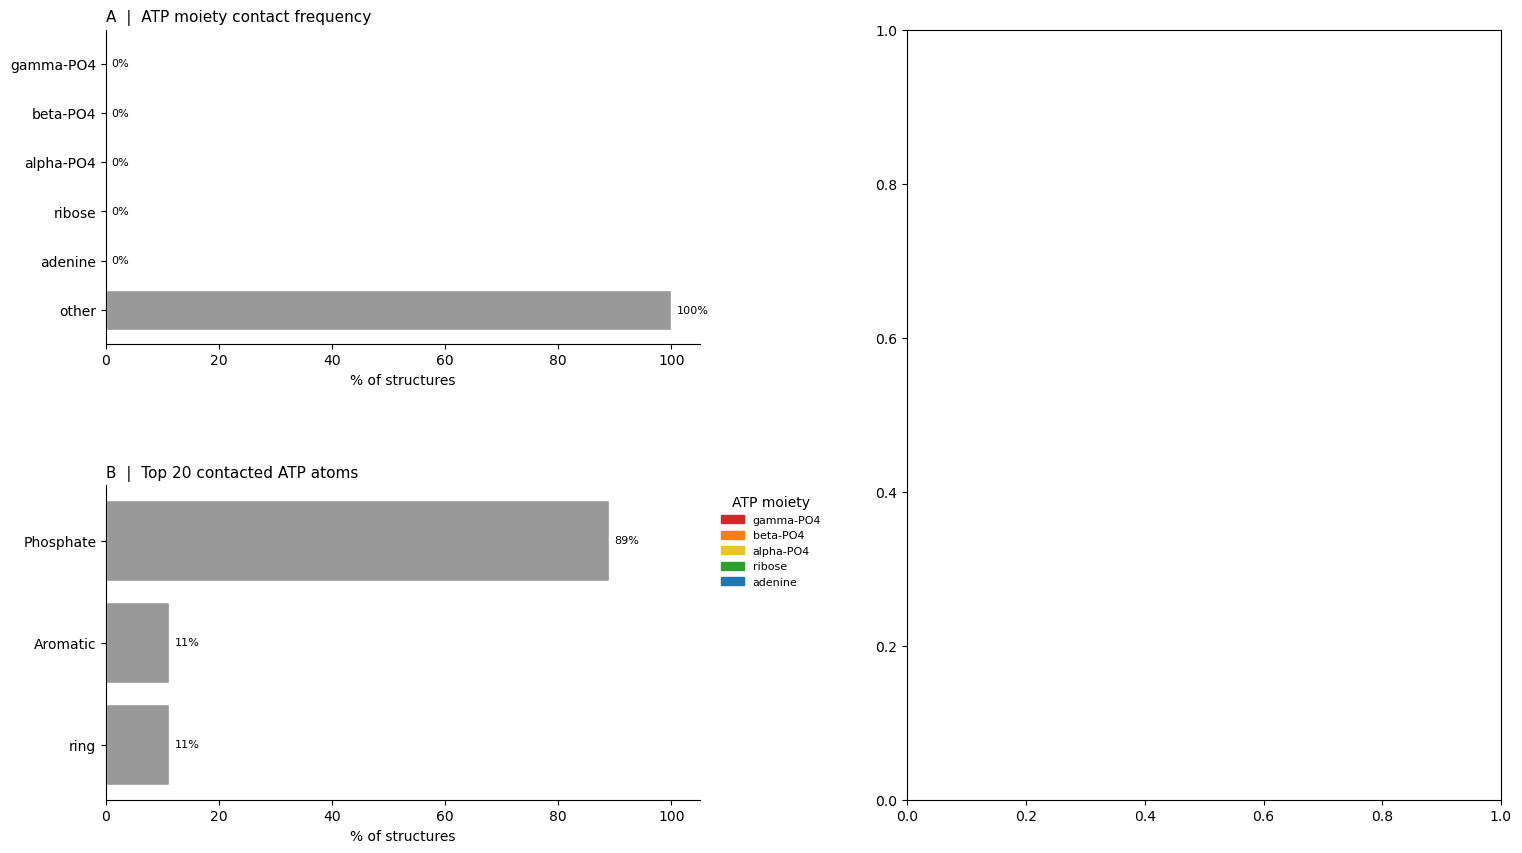

In [17]:

# ── 1. Moiety contact frequency (% of structures contacting each ATP moiety) ──
n_structs = df_all['pdb_id'].nunique()

moiety_freq = (
    df_all[df_all['atp_moiety'] != '']          # skip rows without atom info
        .drop_duplicates(['pdb_id', 'atp_moiety'])
        .groupby('atp_moiety')['pdb_id']
        .count()
        .reindex(MOIETY_ORDER, fill_value=0)
        / n_structs * 100
)

# ── 2. Per-atom contact frequency: top N most-contacted ATP atoms ──────────────
TOP_ATOMS = 20
atom_freq = (
    df_all[df_all['atp_atom'].str.strip() != '']
        .drop_duplicates(['pdb_id', 'atp_atom'])
        .groupby('atp_atom')['pdb_id']
        .count()
        .sort_values(ascending=False)
        .head(TOP_ATOMS)
        / n_structs * 100
)
atom_moiety_map = {a: atp_moiety(a) for a in atom_freq.index}
atom_colors = [MOIETY_COLOR.get(atom_moiety_map[a], '#999') for a in atom_freq.index]

# ── 3. Residue × moiety heatmap (% of structures) ─────────────────────────────
res_moiety = (
    df_all[df_all['atp_moiety'].isin(MOIETY_ORDER[:-1])]   # exclude 'other'
        .drop_duplicates(['pdb_id', 'res_type', 'atp_moiety'])
        .groupby(['res_type', 'atp_moiety'])['pdb_id']
        .count()
        .unstack(fill_value=0)
        .reindex(columns=MOIETY_ORDER[:-1], fill_value=0)
)
# Keep residue types that appear in ≥ 5% of structures for any moiety
res_mask = (res_moiety / n_structs * 100 >= 5).any(axis=1)
res_moiety = res_moiety[res_mask] / n_structs * 100

# ── Plots ──────────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(18, 10))
gs  = fig.add_gridspec(2, 2, hspace=0.45, wspace=0.35)

# (A) Moiety contact frequency
ax_a = fig.add_subplot(gs[0, 0])
bar_colors_m = [MOIETY_COLOR[m] for m in moiety_freq.index]
ax_a.barh(moiety_freq.index, moiety_freq.values, color=bar_colors_m, edgecolor='white')
ax_a.set_xlabel('% of structures')
ax_a.set_title('A  |  ATP moiety contact frequency', fontsize=11, loc='left')
ax_a.invert_yaxis()
ax_a.set_xlim(0, 105)
for v, lbl in zip(moiety_freq.values, moiety_freq.index):
    ax_a.text(v + 1, lbl, f'{v:.0f}%', va='center', fontsize=8)
for sp in ['top', 'right']:
    ax_a.spines[sp].set_visible(False)

# (B) Per-atom contact frequency
ax_b = fig.add_subplot(gs[1, 0])
ax_b.barh(atom_freq.index, atom_freq.values, color=atom_colors, edgecolor='white')
ax_b.set_xlabel('% of structures')
ax_b.set_title(f'B  |  Top {TOP_ATOMS} contacted ATP atoms', fontsize=11, loc='left')
ax_b.invert_yaxis()
ax_b.set_xlim(0, 105)
for v, lbl in zip(atom_freq.values, atom_freq.index):
    ax_b.text(v + 1, lbl, f'{v:.0f}%', va='center', fontsize=8)
for sp in ['top', 'right']:
    ax_b.spines[sp].set_visible(False)

# Legend for moiety colours
legend_patches = [mpatches.Patch(color=MOIETY_COLOR[m], label=m) for m in MOIETY_ORDER[:-1]]
ax_b.legend(handles=legend_patches, fontsize=8, frameon=False,
            bbox_to_anchor=(1.02, 1), loc='upper left', title='ATP moiety')

# (C) Residue × moiety heatmap
ax_c = fig.add_subplot(gs[:, 1])
sns.heatmap(
    res_moiety,
    ax=ax_c,
    cmap='YlOrRd',
    linewidths=0.4,
    linecolor='white',
    annot=True,
    fmt='.0f',
    cbar_kws={'label': '% of structures', 'shrink': 0.6},
    xticklabels=[c.replace('-', '\n') for c in res_moiety.columns],
)
ax_c.set_title('C  |  Residue × ATP moiety contact matrix\n(% of structures)', fontsize=11, loc='left')
ax_c.set_xlabel('ATP moiety')
ax_c.set_ylabel('Residue type')
ax_c.tick_params(axis='x', labelsize=9)
ax_c.tick_params(axis='y', labelsize=8, rotation=0)

fig.suptitle(
    f'ATP Atom-Level Contact Analysis  —  {n_structs} structures',
    fontsize=13, y=1.01
)
fig.savefig(Path(PLOT_DIR) / 'atp_moiety_contacts.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved atp_moiety_contacts.png')

# Print summary table
print('\nMoiety contact summary:')
print(f'  {"Moiety":<15}  {"% structures":>14}')
for m, v in moiety_freq.items():
    print(f'  {m:<15}  {v:>13.0f}%')

print(f'\nTop contacted atoms (across {n_structs} structures):')
for atom, pct in atom_freq.items():
    print(f'  {atom:<6}  [{atp_moiety(atom):<12}]  {pct:.0f}%')


In [ ]:

# For each unique (res_type, itype, atp_moiety) triplet, list every PDB ID
# that contains at least one instance of that contact.
#
# Columns:
#   res_type    – protein residue type (e.g. LYS)
#   itype       – interaction type (e.g. HBond_Don, Salt, Metal …)
#   atp_moiety  – ATP structural region (gamma-PO4 / beta-PO4 / alpha-PO4 / ribose / adenine / other)
#   n_structures – number of distinct PDB structures with this contact
#   pdb_ids     – semicolon-separated, alphabetically sorted list of those PDB IDs

interaction_pdb_list = (
    df_all[df_all['atp_moiety'] != '']          # drop rows where atom was not resolved
        .drop_duplicates(['pdb_id', 'res_type', 'itype', 'atp_moiety'])
        .groupby(['res_type', 'itype', 'atp_moiety'])['pdb_id']
        .agg(n_structures='count',
             pdb_ids=lambda ids: ';'.join(sorted(ids)))
        .reset_index()
        .sort_values(['atp_moiety', 'res_type', 'itype'])
        .reset_index(drop=True)
)

OUT_PATH = Path(OUTPUT_DIR) / 'interaction_pdb_list.csv'
interaction_pdb_list.to_csv(OUT_PATH, index=False)

print(f'Saved {OUT_PATH}')
print(f'Rows (unique triplets): {len(interaction_pdb_list):,}')
print()
print(interaction_pdb_list.head(20).to_string(index=False))


Saved output/binding/interaction_pdb_list.csv
Rows (unique triplets): 79

res_type     itype atp_moiety  n_structures                                                                                                                                                                                                                                                                                                               pdb_ids
     ALA HBond_Acc      other             9                                                                                                                                                                                                                                                                          11KK;1GZ3;1GZ4;1J1Z;1J21;1KH2;1KP2;1KP3;1L2T
     ALA HBond_Don      other            17                                                                                                                                                                               

---
## Step 9 — Design insights for complementary binding proteins

The table and plot below summarise which ATP faces are **over-engaged** by the
native protein and which are **most exposed** — the exposed faces are the
prime targets for a designed complementary binder.

**Conceptual design rules:**
1. **γ-phosphate reader** — The most nucleotide-specific handle. Design a Lys/Arg
   loop that coordinates the γ-phosphate; the complex only forms when ATP (not ADP)
   is present.
2. **Adenine face stacking** — Aromatic (Phe, Tyr, Trp) residues stacking on the
   adenine ring are highly conserved but often engage only one face. A complementary
   binder can cap the other face.
3. **Ribose hydroxyl H-bonds** — Ser/Thr H-bonds to the 2'- and 3'-OH groups add
   ATP vs. GTP selectivity.
4. **Neoepitope strategy** — Look for clusters where ATP binding exposes a flat
   surface on the protein (β-strand, helix face). That surface is the induced
   assembly site for a second protein.

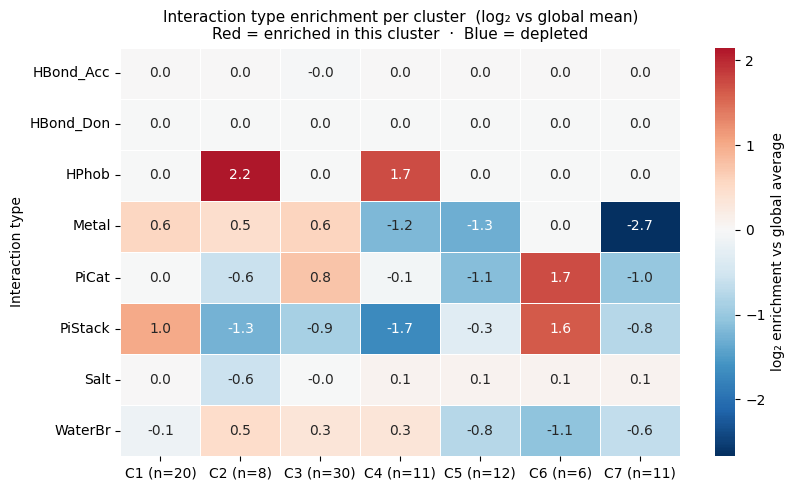

Saved cluster_enrichment.png


In [ ]:
# Per-cluster: which interaction types are enriched vs the global average?
global_freq = itype_conservation / 100  # as fraction

enrichment = {}
for cid in range(1, N_CLUSTERS + 1):
    members = fp[fp['cluster'] == cid].index.tolist()
    cl_df   = df_all[df_all['pdb_id'].isin(members)]
    n_cl    = len(members)
    cl_freq = (
        cl_df.drop_duplicates(['pdb_id', 'itype'])
             .groupby('itype')['pdb_id']
             .count() / n_cl
    )
    # log2 enrichment vs global
    enrich = np.log2((cl_freq + 0.01) / (global_freq + 0.01))
    enrichment[f'C{cid} (n={n_cl})'] = enrich

enrich_df = pd.DataFrame(enrichment).fillna(0)

fig, ax = plt.subplots(figsize=(max(8, N_CLUSTERS * 1.2), 5))
sns.heatmap(
    enrich_df,
    ax=ax,
    cmap='RdBu_r',
    center=0,
    linewidths=0.5,
    linecolor='white',
    annot=True,
    fmt='.1f',
    cbar_kws={'label': 'log\u2082 enrichment vs global average'},
)
ax.set_title(
    'Interaction type enrichment per cluster  (log\u2082 vs global mean)\n'
    'Red = enriched in this cluster  ·  Blue = depleted',
    fontsize=11
)
ax.set_ylabel('Interaction type')
plt.tight_layout()
fig.savefig(Path(PLOT_DIR) / 'cluster_enrichment.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved cluster_enrichment.png')

---
## Step 10 — Export cluster summaries
Saves a JSON summary of each cluster (member PDB IDs and top signature features)
for downstream use.

In [ ]:
summary = []
for cid in range(1, N_CLUSTERS + 1):
    members = fp[fp['cluster'] == cid].index.tolist()
    cl_df   = df_all[df_all['pdb_id'].isin(members)]

    top = (
        cl_df.drop_duplicates(['pdb_id', 'res_type', 'itype'])
             .groupby(['res_type', 'itype'])
             .size()
             .reset_index(name='n')
             .sort_values('n', ascending=False)
             .head(8)
    )
    summary.append({
        'cluster': cid,
        'n_structures': len(members),
        'pdb_ids': members,
        'signature_features': [
            {'res_type': r, 'itype': i, 'n_structs': int(n)}
            for r, i, n in zip(top['res_type'], top['itype'], top['n'])
        ],
    })

out_path = Path(OUTPUT_DIR) / 'cluster_summary.json'
with open(out_path, 'w') as f:
    json.dump(summary, f, indent=2)

print(f'Saved {out_path}')
print(f'\nOutput files in {OUTPUT_DIR}/')
for p in sorted(Path(OUTPUT_DIR).iterdir()):
    if p.is_file():
        print(f'  {p.name:40s}  {p.stat().st_size // 1024:6d} KB')

Saved output/binding/cluster_summary.json

Output files in output/binding/
  atp_interactions.csv                         194 KB
  cluster_assignments.csv                        0 KB
  cluster_summary.json                           7 KB
  interaction_pdb_list.csv                       8 KB


---
## Step 11 — PyMOL sessions per cluster

Randomly samples `N_PYMOL_PER_CLUSTER` PDB structures from each cluster, runs PLIP
with its `-y` flag to annotate interactions, then applies the visual preferences
from section 2b via the `pymol2` API.

Sessions are saved to `OUTPUT_DIR/pymol_sessions/` as `cluster{N}_{PDBID}.pse`.
Double-click any `.pse` to open directly in PyMOL with all ATP contacts pre-annotated.

In [ ]:
import random
import glob
import tempfile

try:
    from pymol2 import PyMOL as _PyMOL
    _has_pymol2 = True
    print('pymol2 available — visual preferences will be applied to sessions.')
except ImportError:
    _has_pymol2 = False
    print('pymol2 not importable — sessions saved without visual preferences.\n'
          'Install with:  conda install -c conda-forge pymol-open-source')

PYMOL_SESSION_DIR = Path(OUTPUT_DIR) / 'pymol_sessions'
PYMOL_SESSION_DIR.mkdir(parents=True, exist_ok=True)


def _apply_settings_to_pse(pse_path: str) -> None:
    with _PyMOL() as p:
        p.cmd.load(pse_path)
        for line in PYMOL_SETTINGS.splitlines():
            line = line.strip()
            if line and not line.startswith('#'):
                try:
                    p.cmd.do(line)
                except Exception:
                    pass
        p.cmd.save(pse_path)


rng = random.Random(PYMOL_SEED)
sampled = {}
for cid in range(1, N_CLUSTERS + 1):
    members = fp[fp['cluster'] == cid].index.tolist()
    k = min(N_PYMOL_PER_CLUSTER, len(members))
    sampled[cid] = rng.sample(members, k)

print('Sampled structures per cluster:')
for cid, pids in sampled.items():
    print(f'  Cluster {cid}: {pids}')
print()

failed = []
for cid, pids in sampled.items():
    for pdb_id in pids:
        pdb_path = Path(PDB_CACHE_DIR) / f'{pdb_id.lower()}.pdb'
        dest     = PYMOL_SESSION_DIR / f'cluster{cid}_{pdb_id}.pse'
        if dest.exists():
            print(f'  {pdb_id}: session already cached, skipping.')
            continue
        if not pdb_path.exists():
            print(f'  {pdb_id}: PDB file not found in cache, skipping.')
            failed.append(pdb_id)
            continue
        with tempfile.TemporaryDirectory() as tmp:
            subprocess.run(
                [PLIP_EXE, '-f', str(pdb_path), '-y', '-s', '-o', tmp],
                capture_output=True, text=True,
            )
            pse_files = glob.glob(os.path.join(tmp, '*.pse'))
            if pse_files:
                shutil.copy(pse_files[0], str(dest))
                if _has_pymol2:
                    _apply_settings_to_pse(str(dest))
                print(f'  Cluster {cid} | {pdb_id}: saved {dest.name}')
            else:
                print(f'  Cluster {cid} | {pdb_id}: PLIP produced no .pse '
                      f'(no detectable ATP binding site)')
                failed.append(pdb_id)

print(f'\nDone.  Sessions saved to {PYMOL_SESSION_DIR}/')
if failed:
    print(f'Failed / no session: {failed}')

pymol2 available — visual preferences will be applied to sessions.
Sampled structures per cluster:
  Cluster 1: ['1CSN']
  Cluster 2: ['10TZ']
  Cluster 3: ['1LHR']
  Cluster 4: ['1GZ4']
  Cluster 5: ['1DO0']
  Cluster 6: ['1B76']
  Cluster 7: ['1A0I']

PyMOL>set specular, 0
 Setting: specular set to 0.00000.
PyMOL>set ray_shadow, off
 Setting: ray_shadow set to off.
PyMOL>set antialias, 2
 Setting: antialias set to 2.
PyMOL>set ray_trace_mode, 1
 Setting: ray_trace_mode set to 1.
PyMOL>set ray_trace_disco_factor, 1
 Setting: ray_trace_disco_factor set to 1.00000.
PyMOL>set ray_trace_gain, 0.1
 Setting: ray_trace_gain set to 0.10000.
PyMOL>set power, 0.2
 Setting: power set to 0.20000.
PyMOL>set ambient, 0.4
 Setting: ambient set to 0.40000.
PyMOL>set direct, 0.45
 Setting: direct set to 0.45000.
PyMOL>set cartoon_sampling, 10
 Setting: cartoon_sampling set to 10.
PyMOL>set ray_trace_color, black
 Setting: ray_trace_color set to black.
PyMOL>set seq_view, 1
 Setting: seq_view set to on